# What does deterministic scenario re-planning add?

**Question:** How much does a cheap deterministic re-solve improve on the best plan fixed before each geological draw?

**Level:** 3 · comparison with published methods

**Prerequisites:** Complete uncertainty lessons 01 and 02 first.

**Reading time:** 24 minutes


## Objectives

This lesson measures what deterministic re-planning can establish on a small PhaseFlow case. Before observing any draw, it selects one fixed schedule with the highest mean value across the shared ensemble. For every synthetic value draw, a node-bounded C-PIT[D] neighbourhood search starts from that same schedule. You will inspect paired NPV gains, feasibility-preserving search settings, and the limits of interpreting a local-search estimate as a lower bound on EVPI. This is a computational experiment, not a stochastic mine plan.


## Setup

Install the pinned method package for this lesson from the repository root. The imports cell reports the active versions; no notebook cell installs packages.

```bash
pip install oreblocks==0.6.5 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Import the pipeline and package APIs used in the lesson.
import dataclasses
import importlib.metadata as metadata
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path('../../../data-pipeline').resolve()))
from pipeline.io.schema import Case, DepositSpec, Scenario
from pipeline.model.instances import build_instance
import oreblocks as ob
for package in ('oreblocks', 'numpy', 'scipy', 'matplotlib'):
    print(package, metadata.version(package))

oreblocks 0.6.5
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2


## Data

The PhaseFlow MIT-licensed teaching pipeline builds a declared synthetic vein (4×4×3 blocks, seed 31, four periods, 8% discount). The value ensemble contains 24 equally weighted, spatially correlated synthetic draws from OreBlocks 0.6.5, using sigma 0.25, a two-block smoothing scale, and seed 19. These are not conditional simulations and contain no drillhole conditioning. The same resource, precedence, discount and horizon inputs are held fixed across draws; only block values change. Therefore, the experiment isolates value changes and cannot support claims about uncertain tonnage, costs, capacity, or actual geological probabilities.

## Method

For a period assignment tau and value vector v, discounted value is V(tau,v)=sum[b:tau_b>=0] v_b(1+rho)^(-tau_b). The ex-ante policy is selected once by maximizing mean NPV across the seeded draws. On each draw, node-bounded C-PIT[D] restricted MILPs search from the same feasible starting schedule. A fixed MIP gap, neighbourhood size, round count and seed schedule make the experiment reproducible. Each restricted MILP stops at a 2,000-node limit or its 1e-5 gap target, and its receipt states whether optimality was proven; randomized neighbourhood selection is still heuristic. We compare each resulting feasible NPV with the same policy's NPV on that draw. The average improvement is a lower bound on EVPI; it is not a globally optimal two-stage stochastic solution.


### Step 1: build the declared case

Declare the exact 48-block teaching case used in lessons 01 and 02, then build it through PhaseFlow's named pipeline. The contract report and block count let you detect input drift before attributing a result to uncertainty. The scenario definition, rather than a baked schedule, is the input to every method below.

In [2]:
# Build the declared synthetic case through the product pipeline.
case = Case(
    id='uncertainty-vein-4x4x3', category='teaching',
    title_en='Small synthetic vein', title_es='Veta sintetica pequena',
    deposit=DepositSpec(kind='twin', archetype='vein', dims=(4, 4, 3), seed=31),
    scenario=Scenario(periods=4, discount_rate=0.08,
        capacity_fraction=(0.70, 0.50),
        resource_names=('mining', 'processing')),
)
instance = build_instance(case)
print('contract accepted:', instance.report.ok, '| blocks:', instance.n_blocks)

contract accepted: True | blocks: 48


### Step 2: prepare the reference and fixed menu

Solve the forecast case once with the package's expected-time procedure. This is the plan available before geological outcomes are known. Retaining the whole candidate alongside two alternative package schedules gives the decision maker a finite, explicitly defined menu; it is not the set of every feasible plan.

In [3]:
# Compute forecast and alternate fixed candidates before observing draws.
forecast, _ = ob.solve_cpit(
    instance.cpit, instance.precedence, method='expected',
    local_search=True,
)
gershon_fixed, _ = ob.solve_cpit(
    instance.cpit, instance.precedence, method='gershon',
    local_search=True,
)
greedy_fixed, _ = ob.solve_cpit(
    instance.cpit, instance.precedence, method='greedy',
    local_search=True,
)
print(forecast.method, round(forecast.npv, 2))
print(gershon_fixed.method, round(gershon_fixed.npv, 2))
print(greedy_fixed.method, round(greedy_fixed.npv, 2))

toposort:expected[r1]+shift-ls 179191.57
toposort:gershon+shift-ls -74237.99
toposort:greedy+shift-ls 179593.14


### Step 3: generate common realisations

Generate the seeded ensemble through the package API. The same values are reused in every later cell, which makes comparisons paired: differences cannot be explained by one method receiving easier draws. Confirm the draw count and seed as part of the evidence trail.

In [4]:
# Generate a reproducible ensemble through the package API.
ensemble = ob.perturb_values(
    instance.cpit.value, instance.x, instance.y, instance.level,
    n=24, sigma=0.25, correlation_blocks=2.0, seed=19,
)
print('realisations:', ensemble.n_realisations, '| seed:', ensemble.seed)

realisations: 24 | seed: 19


### Step 4: score the fixed menu before re-planning

Evaluate every fixed candidate on every draw. The matrix lets us select one ex-ante policy by its mean and also shows how the finite menu's winner varies after observing a draw. That per-draw winner is a diagnostic oracle only; it is not used as the baseline for re-planning value.


In [5]:
# Score every fixed candidate on every shared value draw.
fixed_schedules = {
    forecast.method: forecast.period_of_block,
    gershon_fixed.method: gershon_fixed.period_of_block,
    greedy_fixed.method: greedy_fixed.period_of_block,
}
fixed_scores = ob.evaluate_across(
    instance.cpit, ensemble, fixed_schedules,
)
print('best by mean:', fixed_scores.best_by_expected)
print('best fixed mean:', round(float(fixed_scores.expected.max()), 2))

best by mean: toposort:expected[r1]+shift-ls
best fixed mean: 173035.23


### Step 5: re-plan from one fixed policy

For each value draw, copy the same ex-ante best fixed schedule into the draw-specific CPIT and run OreBlocks' node-bounded C-PIT[D] neighbourhood search. The restricted MILPs use a fixed gap and seed schedule; the outer randomized neighbourhood search remains heuristic. Its feasible mean is a lower bound on EVPI, not a global two-stage optimum. We retain each starting NPV and assert the search never degrades it. The restricted solves use a deterministic limit of 2,000 branch-and-bound nodes, preserve each feasible incumbent, and report optimality only when proven.


## Comparison

Blom, Pearce and Cote describe resolving deterministic instances under geological uncertainty. This lesson studies that practical pattern with paired value draws. C-PIT[D] search uses node-bounded MILPs around one ex-ante policy; each receipt reports proof status and repeated neighbourhood selection remains heuristic. It is distinct from a globally optimal stochastic programme and cannot certify EVPI. The experiment is limited to a 48-block synthetic vein and 24 seeded, equally weighted draws.


In [6]:
# Re-plan every draw from the same highest-mean fixed policy.
replanned = []
replan_values = []
best_fixed_index = int(np.argmax(fixed_scores.expected))
fixed_ex_ante = fixed_scores.matrix[best_fixed_index]
fixed_method = fixed_scores.method_ids[best_fixed_index]
fixed_plan = np.asarray(fixed_schedules[fixed_method], dtype=np.int64)
for k, draw_values in enumerate(ensemble.values):
    draw_cpit = dataclasses.replace(instance.cpit, value=draw_values)
    start_npv = float(fixed_ex_ante[k])
    start = ob.ScheduleResult(
        method=f'fixed:{fixed_method}', period_of_block=fixed_plan.copy(), npv=start_npv,
    )
    schedule = ob.exact_local_search(
        draw_cpit, instance.precedence, start, d_max=48, rounds=16,
        seed=31 + k, time_limit=None, node_limit=2_000, mip_gap=1e-5,
    )
    if schedule.npv < start_npv - 1e-6 * max(1.0, abs(start_npv)):
        raise AssertionError(f're-plan degraded the fixed policy on draw {k}')
    replanned.append(schedule)
    replan_values.append(max(start_npv, float(schedule.npv)))
replan_values = np.asarray(replan_values)
print('fixed policy:', fixed_method, '| re-solves:', len(replanned),
      '| first NPV:', round(float(replan_values[0]), 2))


fixed policy: toposort:expected[r1]+shift-ls | re-solves: 24 | first NPV: 203306.27


### Step 6: calculate the paired re-planning gain

The ex-ante baseline is the single candidate with the highest mean across all draws. Each re-plan starts from that same policy and may improve it for its observed value vector. We compare each draw's re-planned NPV with that same policy's NPV on the draw; their mean difference is non-negative up to numerical tolerance. Because a local-search heuristic supplies feasible plans rather than global per-draw optima, the measured gain is a lower bound on EVPI for this synthetic ensemble.


In [7]:
# Compare each re-plan to the same ex-ante policy on paired draws.
paired_gain = replan_values - fixed_ex_ante
replan_result = ob.evaluate_across(
    instance.cpit, ensemble, fixed_schedules,
    per_realisation_optimum=replan_values,
)
print('mean re-planning value (lower bound on EVPI):', round(replan_result.value_of_replanning, 2))
print('mean paired gain:', round(float(paired_gain.mean()), 2))
print('P10/P90:', round(float(np.quantile(paired_gain, 0.10)), 2),
      round(float(np.quantile(paired_gain, 0.90)), 2))
print('positive draws:', int(np.count_nonzero(paired_gain > 1e-9)), '/', len(paired_gain))


mean re-planning value (lower bound on EVPI): 60459.19
mean paired gain: 60459.19
P10/P90: 52730.97 68739.14
positive draws: 24 / 24


### Distribution comparison

The left panel compares the forecast policy, the best fixed policy selected by expected value, and the re-planned policy on identical draws. The right panel shows paired gains over that one fixed policy. This exposes distribution and tail behavior while making zero-gain scenarios visible. The 24 draws are a designed experiment, not inferential samples from a calibrated deposit model.


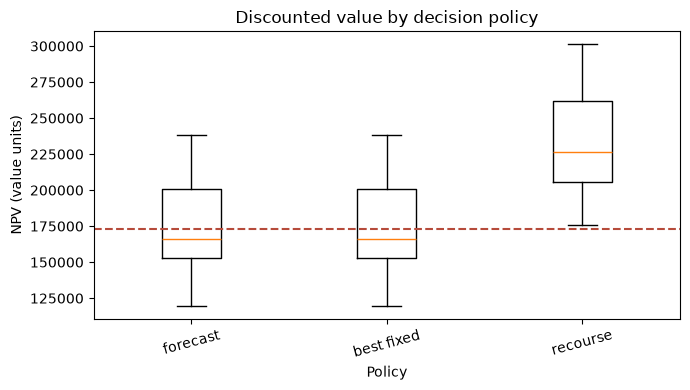

In [8]:
# Compare fixed policies with the value available through scenario recourse.
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([fixed_scores.matrix[0], fixed_ex_ante, replan_values],
    tick_labels=['forecast', 'best fixed', 'recourse'])
ax.axhline(fixed_scores.expected.max(), color='#b64b3b', linestyle='--')
ax.set(title='Discounted value by decision policy',
    xlabel='Policy', ylabel='NPV (value units)')
ax.tick_params(axis='x', rotation=15)
fig.tight_layout()
plt.show()

Each box summarizes discounted values on the same 24 synthetic draws. The forecast and best-fixed policies keep one schedule across every draw; each re-plan starts from the best-fixed schedule and may improve it for that draw. The dashed line marks the ex-ante best fixed plan's mean, not a benchmark optimum. Medians and spread describe this seeded experiment only. Overlap is not a significance test, and P10 is not a guaranteed floor.


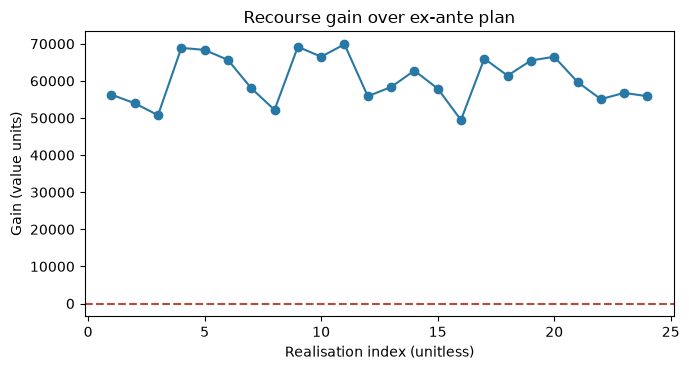

In [9]:
# Plot recourse gains and the zero-gain reference for every draw.
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(np.arange(1, len(paired_gain) + 1), paired_gain,
    marker='o', color='#2878a5')
ax.axhline(0, color='#b64b3b', linestyle='--')
ax.set(title='Recourse gain over ex-ante plan',
    xlabel='Realisation index (unitless)', ylabel='Gain (value units)')
fig.tight_layout()
plt.show()

### Figure 2

Each point is the re-planned NPV minus the NPV of the same best-fixed policy on that draw. Every re-plan starts from the fixed policy, and the restricted search preserves its incumbent; gains should therefore be non-negative up to numerical tolerance. The mean is a feasible lower bound on EVPI because the local search may miss better schedules. It does not certify a global recourse optimum.


### Step 7: compare spatial coherence

The same value draws can produce plans with different spatial layouts. Use OreBlocks' `schedule_coherence` on the ex-ante fixed plan and on each re-planned schedule. The summary reports mean connected components per active period, the pooled share of mined blocks in the largest component, and the tenth percentile of minimum width in blocks. Width here is a geometric proxy, not metres or an operating-width certificate; these summaries do not replace precedence and capacity checks. Because this case perturbs values only, any difference comes from the schedule selected by re-planning, not from changed geometry.


In [10]:
# Measure spatial summaries for the fixed policy and every re-planned schedule.
def geometry_summary(period_assignment):
    period_rows = ob.schedule_coherence(
        period_assignment, instance.x, instance.y, instance.level, n_periods=4,
    )
    active = [row for row in period_rows if row.blocks > 0]
    total_blocks = sum(row.blocks for row in active)
    return {
        'components_per_period': float(np.mean([row.components for row in active])),
        'largest_component_share': sum(row.largest_component for row in active) / total_blocks,
        'minimum_width_blocks': min(row.min_width_blocks for row in active),
    }

fixed_geometry = geometry_summary(fixed_plan)
replanned_geometry = [geometry_summary(row.period_of_block) for row in replanned]
print('fixed components/share/min-width:',
      round(fixed_geometry['components_per_period'], 2),
      round(fixed_geometry['largest_component_share'], 3),
      fixed_geometry['minimum_width_blocks'])
print('re-planned mean components/share:',
      round(float(np.mean([row['components_per_period'] for row in replanned_geometry])), 2),
      round(float(np.mean([row['largest_component_share'] for row in replanned_geometry])), 3))
print('re-planned minimum-width P10:',
      round(float(np.quantile([row['minimum_width_blocks'] for row in replanned_geometry], 0.10)), 2))


fixed components/share/min-width: 3.0 0.438 1
re-planned mean components/share: 1.14 0.929
re-planned minimum-width P10: 1.0


## Results

**Answer:** Across the 24 shared draws, the mean paired re-planning gain was **60,459.19** (P10 **52,730.97**, P90 **68,739.14**), and all **24** draws improved. These measurements use the 48-block synthetic case in this notebook. The mean is a lower bound on EVPI for this run, not EVPI itself.


In [11]:
# Print the computed metrics quoted in the answer.
print(f'mean_gain={paired_gain.mean():.2f}')
print(f'P10={np.quantile(paired_gain, 0.10):.2f}; P90={np.quantile(paired_gain, 0.90):.2f}')
print(f'improved_draws={(paired_gain > 1e-9).mean():.3f}')

mean_gain=60459.19
P10=52730.97; P90=68739.14
improved_draws=1.000


## Summary

The experiment selects one policy before observing value draws, then tests how exact restricted C-PIT[D] solves can improve it after each draw. The feasible paired gain is non-negative up to numerical tolerance and supplies a lower bound on EVPI; the randomized outer search does not certify globally optimal recourse. Conclusions are limited to a 48-block synthetic vein, 24 equiprobable seeded draws, and fixed tonnage and capacity. A field study would need conditional simulations with provenance, calibrated scenario weights, uncertainty in relevant inputs, operational controls, and an optimization method with a globality certificate.


## References

- Blom, Pearce and Cote, deterministic scenario analysis in mining: https://arxiv.org/abs/2403.18213.
- Ramazan and Dimitrakopoulos, two-stage stochastic integer programming: https://doi.org/10.1007/s11081-012-9186-2.
- OreBlocks 0.6.5, `exact_local_search`, `perturb_values` and `evaluate_across`: https://pypi.org/project/oreblocks/.
- PhaseFlow instance schema and builder: `data-pipeline/pipeline/io/schema.py` and `data-pipeline/pipeline/model/instances.py` (MIT).
